<a href="https://colab.research.google.com/github/adeeshajayasinghe/RPAL-Interpreter/blob/main/cnn_demo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import tensorflow as tf
from tensorflow.keras import datasets, layers, models
import matplotlib.pyplot as plt
import numpy as np

In [3]:
(X_train, y_train), (X_test, y_test) = datasets.cifar10.load_data()
X_train.shape

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


(50000, 32, 32, 3)

In [4]:
y_train.shape

(50000, 1)

In [5]:
y_train = y_train.reshape(-1,)
y_train.shape

(50000,)

In [6]:
classes = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]

In [7]:
def plot_sample(X, y, index):
  plt.figure(figsize=(15, 2))
  plt.imshow(X[index])
  plt.xlabel(classes[y[index]])

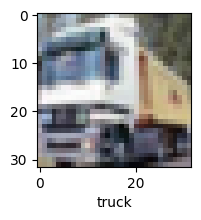

In [8]:
plot_sample(X_train, y_train, 1)

In [9]:
# Normalize pixel value to reside between 0 and 1
X_train = X_train / 255
X_test = X_test / 255

In [18]:
# First test with simple feewforward model and check for the accuracy
ann = models.Sequential([
    layers.Flatten(input_shape=(32, 32, 3)),
    layers.Dense(3000, activation='relu'),
    layers.Dense(1000, activation='relu'),
    layers.Dense(10, activation='sigmoid')
])

ann.compile(
    optimizer='SGD',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'])

ann.fit(X_train ,y_train, epochs=5)

/usr/local/lib/python3.10/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 126s 80ms/step - accuracy: 0.3023 - loss: 1.9357
Epoch 2/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 135s 76ms/step - accuracy: 0.4206 - loss: 1.6457
Epoch 3/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 153s 83ms/step - accuracy: 0.4557 - loss: 1.5491
Epoch 4/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 144s 84ms/step - accuracy: 0.4752 - loss: 1.4945
Epoch 5/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 143s 85ms/step - accuracy: 0.4935 - loss: 1.4387


In [19]:
ann.evaluate(X_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 9s 29ms/step - accuracy: 0.4935 - loss: 1.4426


[1.4514179229736328, 0.49079999327659607]

In [13]:
# You can see the accuracy is 0.49.
# Let's use a cnn

cnn = models.Sequential([
    # cnn
    layers.Conv2D(filters=32, kernel_size=(3, 3), activation='relu', input_shape=(32, 32, 3)),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(filters=64, kernel_size=(3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    #dense
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])

cnn.compile(optimizer='adam',
            loss='sparse_categorical_crossentropy',
            metrics=['accuracy'])

cnn.fit(X_train, y_train, epochs=20)

/usr/local/lib/python3.10/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.3807 - loss: 1.6988
Epoch 2/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.5928 - loss: 1.1597
Epoch 3/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.6472 - loss: 1.0098
Epoch 4/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.6873 - loss: 0.9012
Epoch 5/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.7059 - loss: 0.8397
Epoch 6/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.7319 - loss: 0.7786
Epoch 7/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.7435 - loss: 0.7283
Epoch 8/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.7622 - loss: 0.6848
Epoch 9/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.7778 - loss: 0.6420
Epoch 10/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.7894 - loss: 0.6056
Epoch 11/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.7982 - loss: 0.5752
Epoch 12/20
1563/1563 ━━━━━━━━

In [14]:
cnn.evaluate(X_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.6732 - loss: 1.2289


[1.2293504476547241, 0.6786999702453613]

In [17]:
y_test = y_test.reshape(-1,)
y_test[:5]

array([3, 8, 8, 0, 6], dtype=uint8)

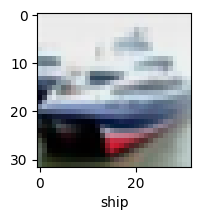

In [18]:
plot_sample(X_test, y_test, 1)

In [19]:
y_pred = cnn.predict(X_test)
y_pred

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


array([[2.04538883e-04, 1.93884953e-05, 2.54090592e-05, ...,
        1.06225094e-07, 2.36600099e-05, 9.21742526e-07],
       [4.05604123e-06, 2.34471392e-02, 2.16058369e-11, ...,
        6.77263065e-15, 9.76159036e-01, 3.89723253e-04],
       [8.44174847e-02, 3.71825188e-01, 4.80159894e-02, ...,
        6.25422515e-04, 3.66333067e-01, 6.11562505e-02],
       ...,
       [1.58408020e-05, 1.89608453e-08, 3.58013920e-02, ...,
        3.71751026e-03, 6.89755325e-05, 1.29485227e-06],
       [1.07885295e-04, 9.98778522e-01, 1.24728222e-05, ...,
        1.42912245e-06, 1.27285216e-09, 1.65624414e-09],
       [1.79822127e-13, 2.48334576e-14, 2.00021155e-09, ...,
        9.99985933e-01, 1.44577015e-15, 7.43181818e-12]], dtype=float32)

In [21]:
y_classes = [np.argmax(element) for element in y_pred]
y_classes[:5]

[3, 8, 1, 0, 4]

In [22]:
y_test[:5]

array([3, 8, 8, 0, 6], dtype=uint8)